# MRI Classifications using Transfer Learning with Xception base model


## Creating a seed for some level of determinism

In [56]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os, random, numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras import regularizers
from tensorflow.keras.applications import Xception
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
import shutil
from sklearn.utils.class_weight import compute_class_weight


seed_value = 42069

random.seed(seed_value)
np.random.seed(seed_value)
tf.random.set_seed(seed_value)



# Data Augmentation

### Through various iterations we have realized that the xception model was able to learn training data very easily  however it struggled to generalize against the validation data hence a somewhat aggresive data augmentation approach was taken to combat that. Utilizing elastic deformation as well as gaussian nose ontop of an array of augmentations in the data generation.

In [57]:


class CustomImageDataGenerator(ImageDataGenerator):
    def __init__(self, elastic_deformation=True, gaussian_noise=True, **kwargs):
        super().__init__(**kwargs)
        self.elastic_deformation = elastic_deformation
        self.gaussian_noise = gaussian_noise
    
    def random_transform(self, x):
        # Perform standard augmentation first
        x = super().random_transform(x)
        
        # Add elastic deformation if enabled
        if self.elastic_deformation:
            x = self.elastic_deformation_augmentation(x)
        
        # Add gaussian noise if enabled
        if self.gaussian_noise:
            x = self.add_gaussian_noise(x)
        
        return x

    def elastic_deformation_augmentation(self, image, alpha=34, sigma=4):
        random_state = np.random.RandomState(None)
        
        shape = image.shape
        dx = np.random.uniform(-1, 1, shape) * alpha
        dy = np.random.uniform(-1, 1, shape) * alpha
        dz = np.random.uniform(-1, 1, shape) * alpha

        dx = gaussian_filter(dx, sigma=sigma, mode="constant", cval=0)
        dy = gaussian_filter(dy, sigma=sigma, mode="constant", cval=0)
        dz = gaussian_filter(dz, sigma=sigma, mode="constant", cval=0)

        distorted_image = ndimage.map_coordinates(image, (dz, dy, dx), order=1, mode='reflect')
        return distorted_image
    
    def add_gaussian_noise(self, image, mean=0, std=0.1):
        noise = np.random.normal(mean, std, image.shape)
        noisy_image = image + noise
        noisy_image = np.clip(noisy_image, 0., 1.)  # Ensure that the values are in [0, 1]
        return noisy_image


# Define directories
data_dir = './dataset_8'  # The directory where the 4 folders (pituitary, glioma, etc.) are located

# Create a custom ImageDataGenerator for training with validation split
train_datagen = CustomImageDataGenerator(
    rescale=1./255,                        # Normalize images
    rotation_range=10,                     # Small random rotations
    width_shift_range=0.3,                 # Small horizontal shifts
    height_shift_range=0.3,                # Small vertical shifts
    shear_range=0.3,                       # Small shear
    zoom_range=0.3,                        # Small zoom                  
    fill_mode='nearest',                   # Filling mode for missing pixels
    validation_split=0.3                   # 30% of data for validation
)

# Create an ImageDataGenerator for validation (without augmentation)
val_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.3)

# Load training data (80% for training)
train_generator = train_datagen.flow_from_directory(
    data_dir,
    target_size=(299, 299),  # Xception expected size
    batch_size=8,
    class_mode='categorical',
    subset='training',  # Only use the training subset
    shuffle=True
)

# Load validation data (20% for validation)
validation_generator = val_datagen.flow_from_directory(
    data_dir,
    target_size=(299, 299),
    batch_size=8,
    class_mode='categorical',
    subset='validation',  # Only use the validation subset
    shuffle=False
)


Found 336 images belonging to 4 classes.
Found 144 images belonging to 4 classes.


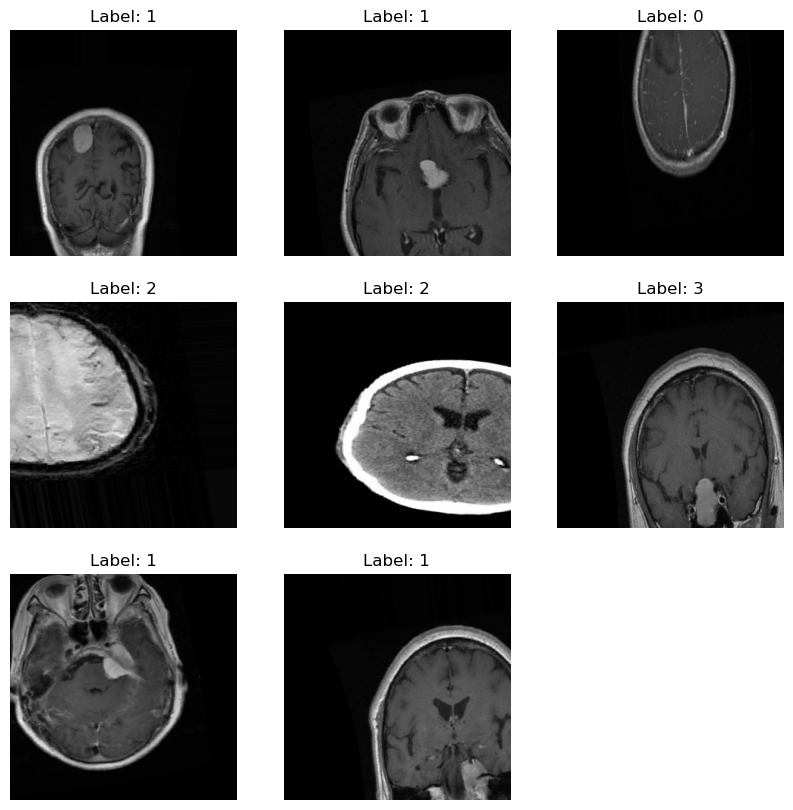

In [58]:
images, labels = next(train_generator)

plt.figure(figsize=(10, 10))
for i in range(len(images)):  # Safer, dynamically matches batch size
    plt.subplot(3, 3, i+1)
    plt.imshow(images[i])
    plt.title(f"Label: {np.argmax(labels[i])}")
    plt.axis('off')
plt.show()

# Model Creation

### Here we initialize the Xception model and set its input shape to 299,299 which is what the base model generally accepts. On top of the base model I have added GlobalAveragepooling which acts as a final pooling layer before the Dense layers. Dense layers are put ontop of the pretrained model to perform task specific classification. 64 was the chosen amount after finetuning over many different iterations. The final dense layer is where the classification happens and is the output. Inbetween a dropout layer is used because large levels of overfitting was being experienced and it was noted that even though 70% is a pretty extreme level, the model was still able to learn regardless.

In [59]:
# Load Xception with ImageNet weights, excluding the top classification layer
base_model = Xception(weights='imagenet', include_top=False, input_shape=(299, 299, 3))

# Freeze the base model layers so they won't be updated during initial training
base_model.trainable = False

# Add custom layers on top of Xception
x = base_model.output
x = GlobalAveragePooling2D()(x)  # Global average pooling to reduce spatial dimensions

# Add L2 regularization to the Dense layer
x = Dense(64, activation='relu', 
          kernel_regularizer=regularizers.l2(0.02))(x)  # L2 regularization with weight decay of 0.01
x = Dropout(0.7)(x)  # Add dropout with 60% rate
x = Dense(4, activation='softmax', 
          kernel_regularizer=regularizers.l2(0.02))(x)  # L2 regularization for final layer as well

# Final model
model = Model(inputs=base_model.input, outputs=x)

# View model summary to ensure correct architecture
model.summary()


Model: "model_4"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_5 (InputLayer)           [(None, 299, 299, 3  0           []                               
                                )]                                                                
                                                                                                  
 block1_conv1 (Conv2D)          (None, 149, 149, 32  864         ['input_5[0][0]']                
                                )                                                                 
                                                                                                  
 block1_conv1_bn (BatchNormaliz  (None, 149, 149, 32  128        ['block1_conv1[0][0]']           
 ation)                         )                                                           

In [60]:
# Compile the model
model.compile(optimizer=Adam(learning_rate=3e-4), loss='categorical_crossentropy', metrics=['accuracy'])


In [61]:
# Define the learning rate scheduler
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5)

class PrintLRCallback(tf.keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        print(f"Learning rate for epoch {epoch+1}: {self.model.optimizer.learning_rate.numpy()}")

# Train with the learning rate scheduler
history = model.fit(
    train_generator,
    epochs=25,
    validation_data=validation_generator,
    callbacks=[lr_scheduler,PrintLRCallback()]
)

Learning rate for epoch 1: 0.0003000000142492354
Epoch 1/25
42/42 [==============================] - 8s 141ms/step - loss: 3.7165 - accuracy: 0.3125 - val_loss: 3.2877 - val_accuracy: 0.5694 - lr: 3.0000e-04
Learning rate for epoch 2: 0.0003000000142492354
Epoch 2/25
42/42 [==============================] - 5s 122ms/step - loss: 3.0744 - accuracy: 0.5119 - val_loss: 2.8094 - val_accuracy: 0.5833 - lr: 3.0000e-04
Learning rate for epoch 3: 0.0003000000142492354
Epoch 3/25
42/42 [==============================] - 5s 130ms/step - loss: 2.6733 - accuracy: 0.5744 - val_loss: 2.4762 - val_accuracy: 0.6944 - lr: 3.0000e-04
Learning rate for epoch 4: 0.0003000000142492354
Epoch 4/25
42/42 [==============================] - 5s 120ms/step - loss: 2.3891 - accuracy: 0.6131 - val_loss: 2.2155 - val_accuracy: 0.6806 - lr: 3.0000e-04
Learning rate for epoch 5: 0.0003000000142492354
Epoch 5/25
42/42 [==============================] - 5s 127ms/step - loss: 2.1769 - accuracy: 0.6071 - val_loss: 2.0152 

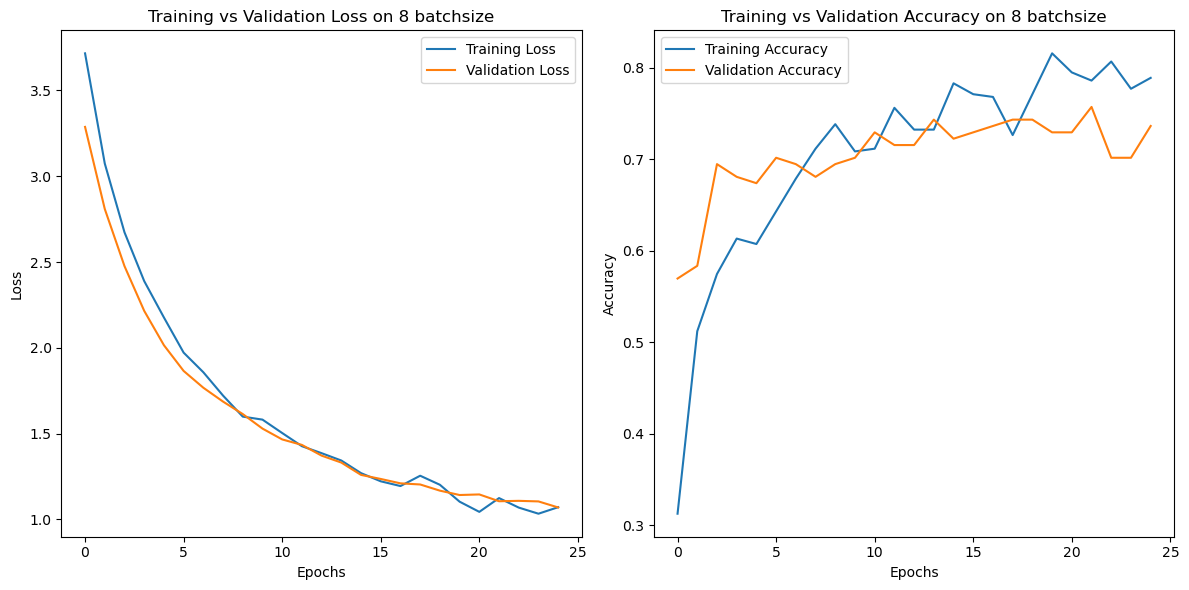

In [62]:
def plot_training_history(history):
    # Plot training vs validation loss
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training vs Validation Loss on 8 batchsize')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Plot training vs validation accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training vs Validation Accuracy on 8 batchsize')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Display the plots
    plt.tight_layout()
    plt.show()

# After your training loop ends, call this function
plot_training_history(history)

In [63]:
for layer in base_model.layers[-10:]:  # Example: Unfreeze the last 30 layers
    layer.trainable = True

# Recompile the model with a learning rate that allows fine-tuning
model.compile(optimizer=Adam(learning_rate=5e-5), loss='categorical_crossentropy', metrics=['accuracy'])

# Define early stopping to stop training if no improvement for 5 epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Define the learning rate scheduler
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

# Define the model checkpoint callback


# Fine-tune the model with early stopping, learning rate scheduler, and checkpointing
history_finetune = model.fit(
    train_generator,
    epochs=20,                           # Fine-tune for more epochs
    validation_data=validation_generator,
    callbacks=[lr_scheduler, early_stopping]  # Use all the callbacks
)

Epoch 1/20
42/42 [==============================] - 7s 130ms/step - loss: 1.3057 - accuracy: 0.6696 - val_loss: 1.0714 - val_accuracy: 0.7292 - lr: 5.0000e-05
Epoch 2/20
42/42 [==============================] - 5s 114ms/step - loss: 1.1227 - accuracy: 0.7530 - val_loss: 1.0637 - val_accuracy: 0.7569 - lr: 5.0000e-05
Epoch 3/20
42/42 [==============================] - 5s 114ms/step - loss: 0.9623 - accuracy: 0.8304 - val_loss: 1.0401 - val_accuracy: 0.7500 - lr: 5.0000e-05
Epoch 4/20
42/42 [==============================] - 5s 117ms/step - loss: 0.9580 - accuracy: 0.8155 - val_loss: 0.9999 - val_accuracy: 0.7431 - lr: 5.0000e-05
Epoch 5/20
42/42 [==============================] - 5s 114ms/step - loss: 0.9102 - accuracy: 0.8423 - val_loss: 0.9884 - val_accuracy: 0.7708 - lr: 5.0000e-05
Epoch 6/20
42/42 [==============================] - 5s 117ms/step - loss: 0.8496 - accuracy: 0.8631 - val_loss: 0.9684 - val_accuracy: 0.7778 - lr: 5.0000e-05
Epoch 7/20
42/42 [============================

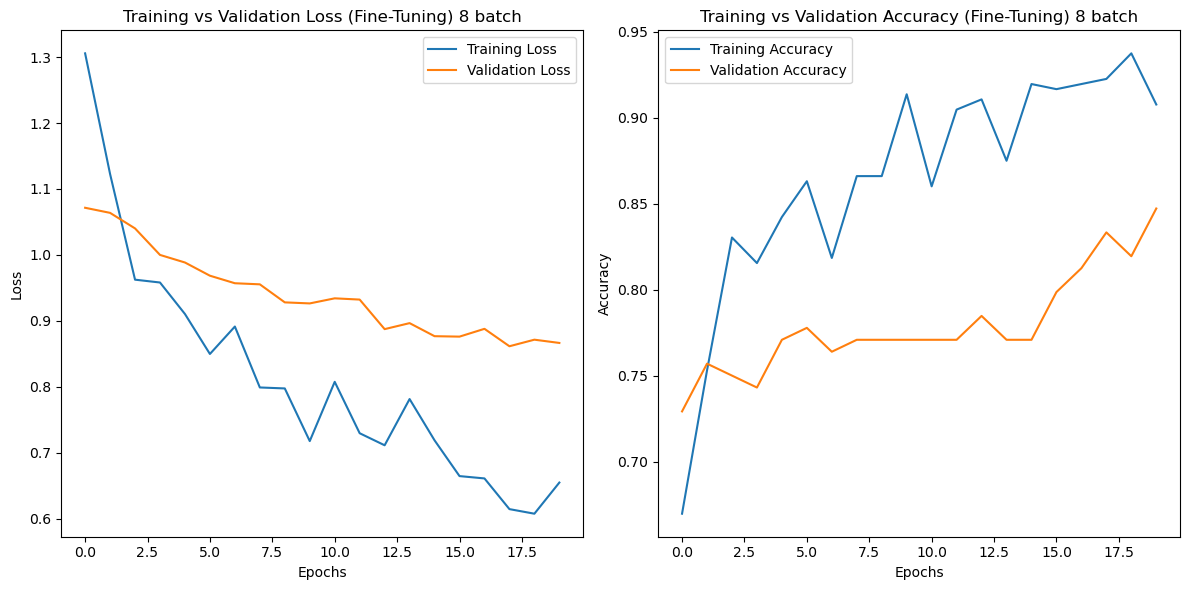

In [64]:
# Function to plot training vs validation loss and accuracy
def plot_finetuning_history(history):
    # Plot training vs validation loss
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training vs Validation Loss (Fine-Tuning) 8 batch')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Plot training vs validation accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training vs Validation Accuracy (Fine-Tuning) 8 batch')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Display the plots
    plt.tight_layout()
    plt.show()

# Plotting the history after fine-tuning
plot_finetuning_history(history_finetune)


Found 480 images belonging to 4 classes.
15/15 [==============================] - 1s 64ms/step - loss: 0.8093 - accuracy: 0.8396
Test Loss: 0.8093
Test Accuracy: 0.8396
15/15 [==============================] - 1s 63ms/step


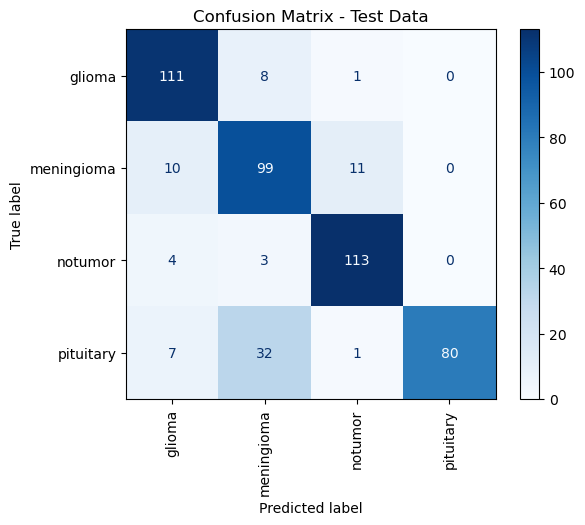

In [65]:
# Define directories (change this path if needed)
test_data_dir = './test'  # This should point to the directory containing your test folders (pituitary, glioma, etc.)

# Create an ImageDataGenerator for the test set (no augmentation, just rescaling)
test_datagen = ImageDataGenerator(rescale=1./255)

# Create a test data generator
test_generator = test_datagen.flow_from_directory(
    test_data_dir,
    target_size=(224, 224),  # Same size used during training
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # We do not shuffle test data
)

# Evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(test_generator)

# Print the results
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# -----------------------------------
# Confusion Matrix for Test Data
# -----------------------------------

# Ensure shuffle=False when creating test_generator to preserve order
y_true = test_generator.classes  # True class indices

# Predict probabilities
y_pred_probs = model.predict(test_generator)
y_pred = np.argmax(y_pred_probs, axis=1)  # Convert to class indices

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Get class names
class_names = list(test_generator.class_indices.keys())

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.title("Confusion Matrix - Test Data")
plt.show()


In [66]:
import shutil

# Ensure your model has made predictions
y_true = test_generator.classes
y_pred_probs = model.predict(test_generator)
y_pred = np.argmax(y_pred_probs, axis=1)

# Confirm class indices mapping
print(test_generator.class_indices)

# Find the index for the 'pituitary' class
pituitary_class_index = test_generator.class_indices['pituitary']

# Find misclassified pituitary images
misclassified_indices = np.where((y_true == pituitary_class_index) & (y_pred != pituitary_class_index))[0]

print(f"Total misclassified pituitary samples: {len(misclassified_indices)}")

# Get file paths of misclassified images
misclassified_files = np.array(test_generator.filepaths)[misclassified_indices]

# Optional: Create a folder to store misclassified pituitary images
save_dir = './misclassified_pituitary'
os.makedirs(save_dir, exist_ok=True)

# Copy files to the new folder
for filepath in misclassified_files:
    shutil.copy(filepath, save_dir)

print(f"Copied {len(misclassified_files)} misclassified pituitary images to '{save_dir}'")


15/15 [==============================] - 1s 69ms/step
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Total misclassified pituitary samples: 40
Copied 40 misclassified pituitary images to './misclassified_pituitary'


In [67]:

# Original dataset location
original_dataset = './dataset_8'

# Location for oversampled dataset
oversampled_dataset = './oversampled_dataset'
os.makedirs(oversampled_dataset, exist_ok=True)

# Step 1: Copy entire original dataset into oversampled_dataset
for class_name in os.listdir(original_dataset):
    src_class_dir = os.path.join(original_dataset, class_name)
    dst_class_dir = os.path.join(oversampled_dataset, class_name)
    
    os.makedirs(dst_class_dir, exist_ok=True)
    
    for file in os.listdir(src_class_dir):
        shutil.copy(os.path.join(src_class_dir, file), dst_class_dir)

print("Original dataset copied to oversampled_dataset.")

# Step 2: Add misclassified pituitary images
misclassified_dir = './misclassified_pituitary'
target_pituitary_dir = os.path.join(oversampled_dataset, 'pituitary')

for file in os.listdir(misclassified_dir):
    src_path = os.path.join(misclassified_dir, file)
    dst_path = os.path.join(target_pituitary_dir, f"oversampled_{file}")  # Optional prefix
    shutil.copy(src_path, dst_path)

print(f"Added {len(os.listdir(misclassified_dir))} misclassified pituitary images to oversampled dataset.")

# ----------------------------------------
# Step 2: Create Data Generators
# ----------------------------------------

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.3,
    height_shift_range=0.3,
    shear_range=0.3,
    zoom_range=0.3,
    fill_mode='nearest',
    validation_split=0.3
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.3
)

train_generator = train_datagen.flow_from_directory(
    './oversampled_dataset',
    target_size=(299, 299),
    batch_size=8,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

validation_generator = val_datagen.flow_from_directory(
    './oversampled_dataset',
    target_size=(299, 299),
    batch_size=8,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# ----------------------------------------
# Step 3: Compute Class Weights
# ----------------------------------------

y_train = train_generator.classes  # True class indices

# Compute balanced class weights
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

# Convert to dict for Keras
class_weights_dict = {i: class_weights_array[i] for i in range(len(class_weights_array))}
print("Class Weights:", class_weights_dict)

# ----------------------------------------
# Step 4: Fine-Tuning Training
# ----------------------------------------

# Optional: Unfreeze last few layers if applicable
for layer in base_model.layers[-10:]:
    layer.trainable = True

# Recompile
model.compile(optimizer=Adam(learning_rate=5e-5), loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks
early_stopping = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

# Train with class weights
history_further_finetune = model.fit(
    train_generator,
    epochs=20,
    validation_data=validation_generator,
    callbacks=[lr_scheduler, early_stopping],
    class_weight=class_weights_dict
)


Original dataset copied to oversampled_dataset.
Added 40 misclassified pituitary images to oversampled dataset.
Found 364 images belonging to 4 classes.
Found 156 images belonging to 4 classes.
Class Weights: {0: 1.0833333333333333, 1: 1.0833333333333333, 2: 1.0833333333333333, 3: 0.8125}
Epoch 1/20
46/46 [==============================] - 10s 174ms/step - loss: 0.6896 - accuracy: 0.8901 - val_loss: 0.7575 - val_accuracy: 0.8526 - lr: 5.0000e-05
Epoch 2/20
46/46 [==============================] - 6s 122ms/step - loss: 0.6587 - accuracy: 0.8956 - val_loss: 0.7399 - val_accuracy: 0.8718 - lr: 5.0000e-05
Epoch 3/20
46/46 [==============================] - 5s 117ms/step - loss: 0.6112 - accuracy: 0.9203 - val_loss: 0.7238 - val_accuracy: 0.8718 - lr: 5.0000e-05
Epoch 4/20
46/46 [==============================] - 5s 119ms/step - loss: 0.6520 - accuracy: 0.9011 - val_loss: 0.6939 - val_accuracy: 0.8974 - lr: 5.0000e-05
Epoch 5/20
46/46 [==============================] - 5s 117ms/step - loss:

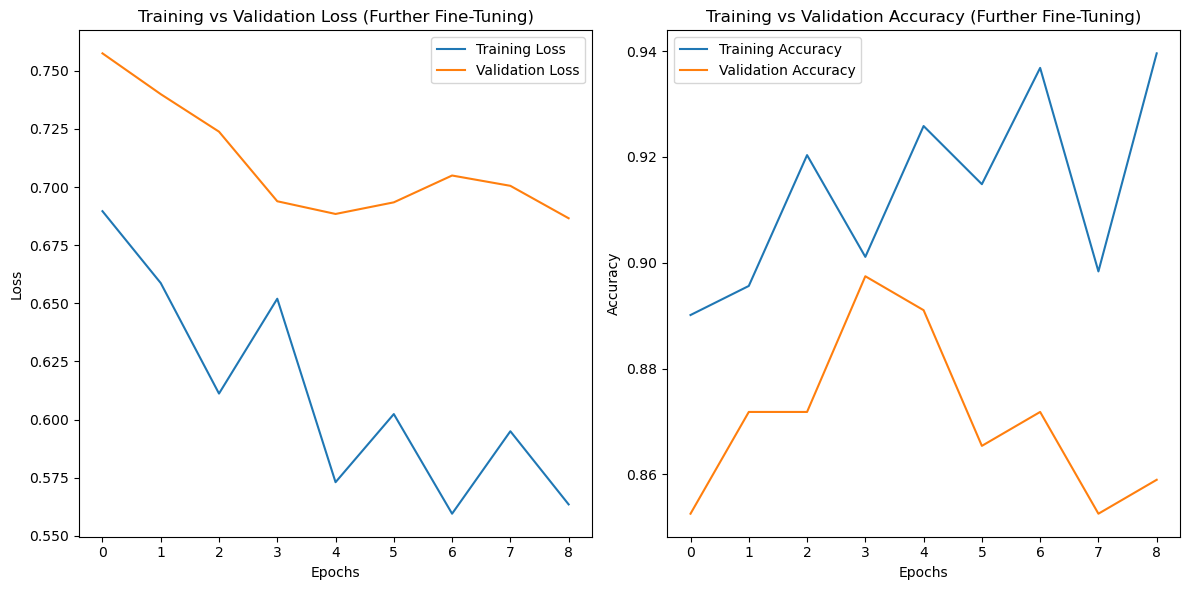

In [68]:
# Function to plot training vs validation loss and accuracy
def plot_further_finetuning_history(history):
    # Plot training vs validation loss
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    
    # Some focused fine-tuning may not have validation loss (if only pituitary data used)
    if 'val_loss' in history.history:
        plt.plot(history.history['val_loss'], label='Validation Loss')
    
    plt.title('Training vs Validation Loss (Further Fine-Tuning)')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Plot training vs validation accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    
    if 'val_accuracy' in history.history:
        plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    
    plt.title('Training vs Validation Accuracy (Further Fine-Tuning)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Display the plots
    plt.tight_layout()
    plt.show()

plot_further_finetuning_history(history_further_finetune)

Found 480 images belonging to 4 classes.
15/15 [==============================] - 1s 62ms/step - loss: 0.6470 - accuracy: 0.8958
Test Loss: 0.6470
Test Accuracy: 0.8958
15/15 [==============================] - 1s 61ms/step


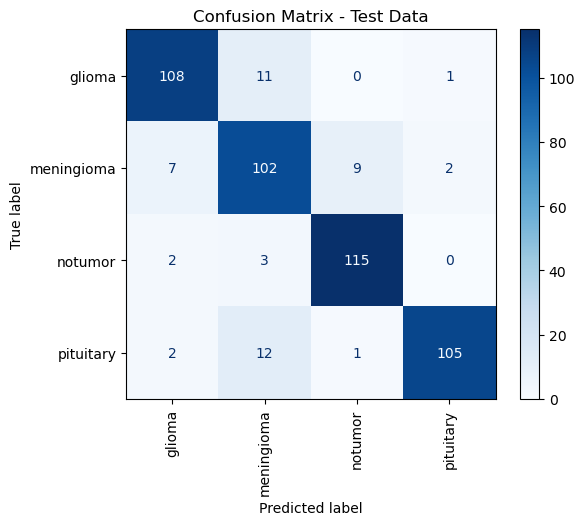

In [69]:
# Define directories (change this path if needed)
test_data_dir = './test'  # This should point to the directory containing your test folders (pituitary, glioma, etc.)

# Create an ImageDataGenerator for the test set (no augmentation, just rescaling)
test_datagen = ImageDataGenerator(rescale=1./255)

# Create a test data generator
test_generator = test_datagen.flow_from_directory(
    test_data_dir,
    target_size=(224, 224),  # Same size used during training
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # We do not shuffle test data
)

# Evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(test_generator)

# Print the results
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# -----------------------------------
# Confusion Matrix for Test Data
# -----------------------------------

# Ensure shuffle=False when creating test_generator to preserve order
y_true = test_generator.classes  # True class indices

# Predict probabilities
y_pred_probs = model.predict(test_generator)
y_pred = np.argmax(y_pred_probs, axis=1)  # Convert to class indices

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Get class names
class_names = list(test_generator.class_indices.keys())

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.title("Confusion Matrix - Test Data")
plt.show()


In [70]:
# Save the entire model (architecture + weights + optimizer state) to a file
model.save('final_model_final.keras')
# Save the entire model (architecture + weights + optimizer state) to a file
model.save('final_model_final.h5')

# Save only the weights of the model
model.save_weights('final_model_weights_final.h5')



In [2]:
model = load_model('final_model.keras')

F:\anaconda3\envs\tf\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
